# DQN — My Implementation Notes

Goal: implement DQN on CartPole-v1 (balance a pole on a cart) and understand every moving part.

Core idea I'm working from: learn `Q(s, a)` = expected discounted future reward if I take action `a` in state `s`.
Once I have Q, my policy is trivially `argmax_a Q(s, a)`.

Why "Deep": I need a neural network because the state is continuous (4 floats for CartPole) — a table won't work.

The trap I need to remember: naive Q-learning + neural net diverges. DQN fixes this with 4 tricks:
1. Experience Replay — train on random past transitions
2. Target Network — frozen copy so the loss target doesn't move every step
3. ε-greedy — try random actions early
4. ε-decay — stop exploring as Q converges

These four tricks ARE the algorithm. Everything else (Double DQN, Dueling, PER) is a variation on them.

## Setup

Dependencies:
- `gymnasium` — env, since OpenAI Gym is deprecated
- `torch` — the NN
- `numpy`, `deque` — buffer + arrays

In [9]:
import random
from collections import deque

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym

# Reproducibility (optional, remove for varied runs)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## Step 1: The Q-Network

I approximate `Q(s, a)` with a small multi-layer perceptron.

- **Input:** the state vector (4 numbers for CartPole: cart pos, cart velocity, pole angle, pole angular velocity)
- **Output:** one Q-value per action (2 for CartPole: push left, push right)

So `Q_net(state)[action]` = "how good is this action in this state".

A tiny MLP (2 hidden layers, 64 units) is enough for CartPole.

In [10]:
class QNetwork(nn.Module):
    """Maps a state to Q-values for every action."""

    def __init__(self, state_size, action_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(state_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, action_size),
        )

    def forward(self, x):
        # x: [batch, state_size]  ->  [batch, action_size]
        return self.net(x)


# Quick sanity check: feed a dummy state, expect 2 outputs
test_net = QNetwork(state_size=4, action_size=2)
dummy_state = torch.zeros(1, 4)
print("Output shape:", test_net(dummy_state).shape)  # torch.Size([1, 2])

Output shape: torch.Size([1, 2])


## Step 2: The Replay Buffer

**Problem:** consecutive transitions `(s_t, a_t, r_t, s_{t+1})` are highly correlated.
Training on them sequentially → catastrophic forgetting & unstable gradients.m

**Solution:** store transitions in a buffer and sample **random mini-batches**.

Each transition is a 5-tuple:
- `state` — what I saw
- `action` — what I did
- `reward` — what I got
- `next_state` — where I landed
- `done` — did the episode end (needed so I don't bootstrap past a terminal state)

`deque(maxlen=N)` automatically drops the oldest sample when full — a free FIFO.

In [11]:
class ReplayBuffer:
    """Stores transitions and serves random mini-batches."""

    def __init__(self, capacity=10_000):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            np.array(states, dtype=np.float32),
            np.array(actions, dtype=np.int64),
            np.array(rewards, dtype=np.float32),
            np.array(next_states, dtype=np.float32),
            np.array(dones, dtype=np.float32),
        )

    def __len__(self):
        return len(self.buffer)


# Sanity check
buf = ReplayBuffer(capacity=5)
for i in range(10):  # push 10, capacity keeps only last 5
    buf.push([i]*4, i % 2, float(i), [i+1]*4, False)
print("Buffer size (capped at 5):", len(buf))

s, a, r, ns, d = buf.sample(3)
print("Sampled state shape:", s.shape)   # (3, 4)
print("Sampled reward shape:", r.shape)  # (3,)

Buffer size (capped at 5): 5
Sampled state shape: (3, 4)
Sampled reward shape: (3,)


## Step 3: The DQN Agent

This class ties everything together. I'll build it in two parts — init + act first, then learn + update.

### Key attributes to notice

| Attribute | Meaning |
|-----------|---------|
| `q_net` | online network — trained every step |
| `target_net` | frozen copy — provides the *target* for the loss |
| `epsilon` | exploration probability, starts at 1.0 |
| `gamma` | discount factor (0.99) |
| `memory` | the replay buffer |

**Why two networks?**
The loss is `Q_net(s,a) ≈ r + γ · max_a' Q_target(s', a')`.
If `Q_target` == `Q_net`, the target moves every time I update — chasing my own tail.
A frozen copy updated only periodically keeps training stable.

In [12]:
class DQNAgent:
    def __init__(self, state_size, action_size):
        self.action_size = action_size
        self.gamma = 0.99          # discount for future rewards
        self.lr = 1e-3
        self.batch_size = 64
        self.epsilon = 1.0         # start fully exploring
        self.epsilon_min = 0.05
        self.epsilon_decay = 0.995

        # Two networks: online (trained) + target (frozen copy)
        self.q_net = QNetwork(state_size, action_size).to(device)
        self.target_net = QNetwork(state_size, action_size).to(device)
        self.target_net.load_state_dict(self.q_net.state_dict())
        self.target_net.eval()     # never train the target net

        self.optimizer = optim.Adam(self.q_net.parameters(), lr=self.lr)
        self.loss_fn = nn.MSELoss()
        self.memory = ReplayBuffer(capacity=10_000)

    def act(self, state, greedy=False):
        """ε-greedy action selection."""
        # Explore: random action with probability epsilon
        if not greedy and random.random() < self.epsilon:
            return random.randrange(self.action_size)

        # Exploit: pick argmax Q(s, ·)
        with torch.no_grad():
            state_t = torch.from_numpy(state).float().unsqueeze(0).to(device)
            q_values = self.q_net(state_t)
        return int(q_values.argmax().item())

    def remember(self, *transition):
        self.memory.push(*transition)

### The `learn()` method — the heart of DQN

This runs one gradient step on a random mini-batch. The logic:

1. Sample `(s, a, r, s', done)` batch from memory
2. **Predict:** `q = q_net(s)[a]` — Q-value of the action I actually took
3. **Target:** `y = r + γ · max_a' Q_target(s', a') · (1 - done)`
   - The `(1 - done)` zeroes the bootstrap at terminal states — I can't earn future reward after dying
4. **Loss:** `MSE(q, y)`
5. `loss.backward()` + `optimizer.step()`

The `gather(1, actions)` line is the trickiest — it indexes the predicted Q-values by the action taken.

In [13]:
def _learn(self):
    """Add to DQNAgent (I define here, attach below)."""
    if len(self.memory) < self.batch_size:
        return  # not enough data yet

    states, actions, rewards, next_states, dones = self.memory.sample(self.batch_size)
    states      = torch.from_numpy(states).to(device)
    actions     = torch.from_numpy(actions).to(device)
    rewards     = torch.from_numpy(rewards).to(device)
    next_states = torch.from_numpy(next_states).to(device)
    dones       = torch.from_numpy(dones).to(device)

    # Q(s, a) for the taken actions
    # q_net(states): [B, A]  ->  gather picks one per row  ->  [B]
    q_values = self.q_net(states).gather(1, actions.unsqueeze(1)).squeeze(1)

    # Bellman target: r + γ * max_a' Q_target(s', a')  (zero if done)
    with torch.no_grad():
        next_q = self.target_net(next_states).max(dim=1)[0]
        targets = rewards + self.gamma * next_q * (1.0 - dones)

    loss = self.loss_fn(q_values, targets)

    self.optimizer.zero_grad()
    loss.backward()
    self.optimizer.step()


def _update_target(self):
    """Hard-copy online weights into the target network."""
    self.target_net.load_state_dict(self.q_net.state_dict())


def _decay_epsilon(self):
    """Linearly shrink exploration over time."""
    self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)


# Attach methods to the class (keeps earlier cells readable)
DQNAgent.learn = _learn
DQNAgent.update_target = _update_target
DQNAgent.decay_epsilon = _decay_epsilon

print("DQNAgent methods attached:", [m for m in dir(DQNAgent) if not m.startswith('_')])

DQNAgent methods attached: ['act', 'decay_epsilon', 'learn', 'remember', 'update_target']


## Step 4: Training Loop

The loop is a standard RL loop with two DQN-specific additions:
for episode in range(N):
state = env.reset()
for t in range(max_steps):
action = agent.act(state) # ε-greedy
next_state, reward, done = env.step(action)
agent.remember(state, action, reward, next_state, done)
agent.learn() # gradient step
state = next_state
if done: break
agent.decay_epsilon()
if episode % 10 == 0:
agent.update_target() # sync frozen net


Key detail: `agent.update_target()` is called every 10 **episodes** here (the original paper used every 1000 **steps**). Either works; episodes are simpler for CartPole.`

In [14]:
def train(episodes=300, max_steps=500):
    env = gym.make("CartPole-v1")
    state_size  = env.observation_space.shape[0]   # 4
    action_size = env.action_space.n               # 2

    agent = DQNAgent(state_size, action_size)
    rewards_history = []

    for ep in range(1, episodes + 1):
        state, _ = env.reset()
        total_reward = 0.0

        for t in range(max_steps):
            action = agent.act(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            agent.remember(state, action, reward, next_state, done)
            agent.learn()

            state = next_state
            total_reward += reward
            if done:
                break

        agent.decay_epsilon()

        # Sync target network every 10 episodes
        if ep % 10 == 0:
            agent.update_target()

        rewards_history.append(total_reward)

        if ep % 20 == 0:
            avg = np.mean(rewards_history[-20:])
            print(f"Ep {ep:3d} | reward={total_reward:5.1f} | avg(last 20)={avg:6.2f} | ε={agent.epsilon:.3f}")

    env.close()
    return agent, rewards_history

## Run It

I expect ~2–4 minutes on CPU. I'll watch the `avg(last 20)` column — it should climb toward 200+ once the agent learns.

In [15]:
agent, rewards = train(episodes=300)

Ep  20 | reward= 10.0 | avg(last 20)= 21.40 | ε=0.905
Ep  40 | reward= 13.0 | avg(last 20)= 20.45 | ε=0.818
Ep  60 | reward= 23.0 | avg(last 20)= 30.75 | ε=0.740
Ep  80 | reward= 39.0 | avg(last 20)= 42.55 | ε=0.670
Ep 100 | reward= 55.0 | avg(last 20)= 33.30 | ε=0.606
Ep 120 | reward= 88.0 | avg(last 20)= 58.30 | ε=0.548
Ep 140 | reward= 79.0 | avg(last 20)= 61.70 | ε=0.496
Ep 160 | reward= 65.0 | avg(last 20)= 65.80 | ε=0.448
Ep 180 | reward= 25.0 | avg(last 20)=102.25 | ε=0.406
Ep 200 | reward=128.0 | avg(last 20)=122.95 | ε=0.367
Ep 220 | reward= 93.0 | avg(last 20)=145.15 | ε=0.332
Ep 240 | reward= 98.0 | avg(last 20)=109.45 | ε=0.300
Ep 260 | reward= 16.0 | avg(last 20)=133.95 | ε=0.272
Ep 280 | reward=194.0 | avg(last 20)=162.65 | ε=0.246
Ep 300 | reward=138.0 | avg(last 20)= 88.80 | ε=0.222


## checking did It Learn?

I'll plot reward per episode. Healthy learning looks like a noisy curve that rises and plateaus near the environment's max (500 for CartPole, though 200 is often enough to be considered "solved").

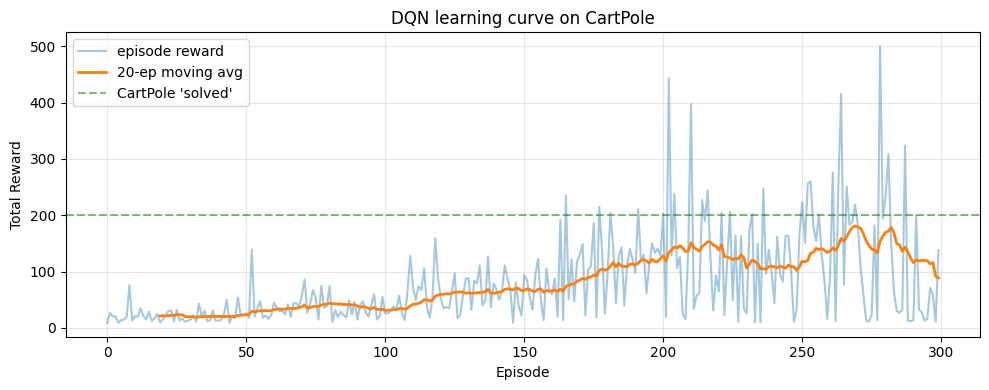

In [16]:
import matplotlib.pyplot as plt

def plot_rewards(rewards, window=20):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(rewards, alpha=0.4, label="episode reward")
    if len(rewards) >= window:
        smooth = np.convolve(rewards, np.ones(window)/window, mode="valid")
        ax.plot(range(window-1, len(rewards)), smooth, linewidth=2,
                label=f"{window}-ep moving avg")
    ax.axhline(200, color="green", linestyle="--", alpha=0.5, label="CartPole 'solved'")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Total Reward")
    ax.set_title("DQN learning curve on CartPole")
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_rewards(rewards)